[OK] Simulation 3 figure successfully saved to: figures/sim3_thermal_photon_statistics.png


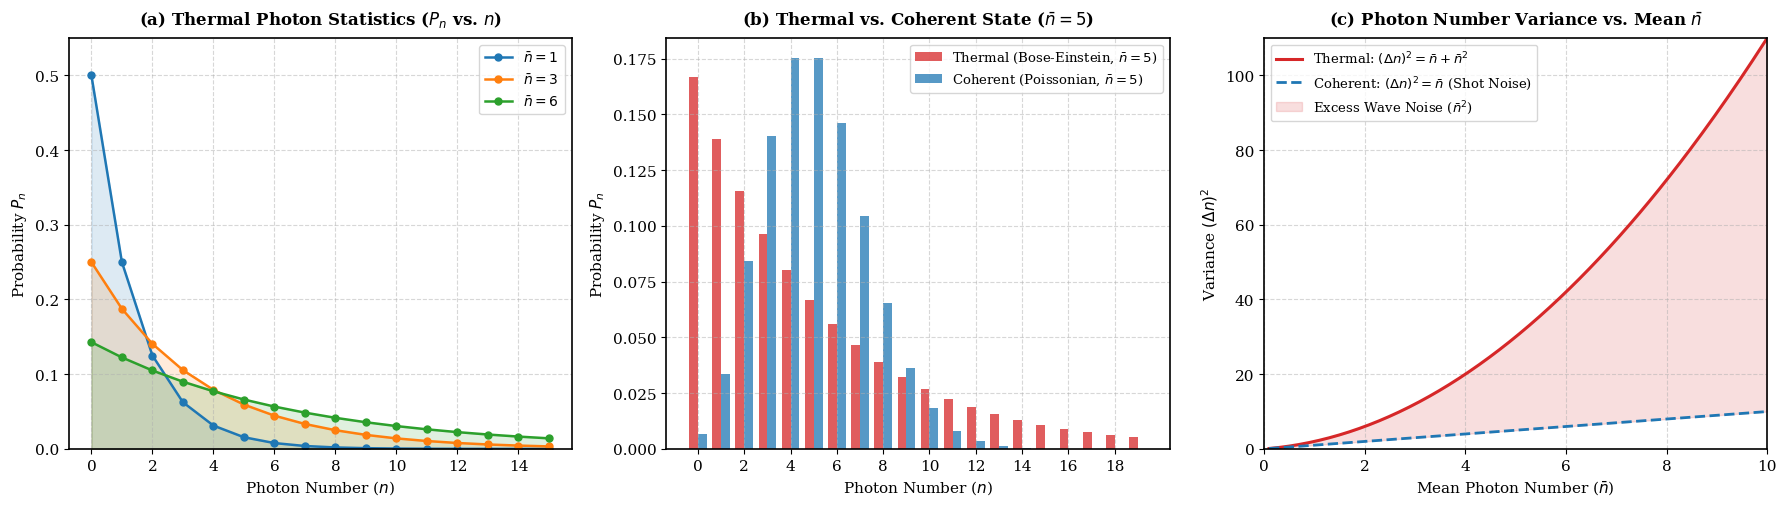

In [1]:
# ==============================================================================
# Simulation 3: Thermal Field Statistics & Photon Bunching
# Reference: Gerry & Knight, "Introductory Quantum Optics", Chapter 2 (Sec 2.5)
# ==============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

# Ensure output directory exists
os.makedirs("figures", exist_ok=True)

# Plot styling configuration
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.linewidth'] = 1.2

# -------------------------------------------------------------
# 1. Theoretical Statistical Distributions
# -------------------------------------------------------------
def bose_einstein_distribution(n_arr, n_bar):
    r"""
    Calculate the thermal (Bose-Einstein) photon number probability distribution:
    P_n = \bar{n}^n / (1 + \bar{n})^(n + 1)
    """
    return (n_bar**n_arr) / ((1.0 + n_bar)**(n_arr + 1))

# -------------------------------------------------------------
# 2. Setup Figure and Subplots
# -------------------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.2))

# --- Subplot (a): Thermal Distributions for Different Mean Photon Numbers ---
n_range = np.arange(0, 16)
n_bars = [1.0, 3.0, 6.0]
colors_thermal = ['#1f77b4', '#ff7f0e', '#2ca02c']

for n_b, col in zip(n_bars, colors_thermal):
    p_th = bose_einstein_distribution(n_range, n_b)
    ax1.plot(n_range, p_th, 'o-', color=col, linewidth=1.8, markersize=5,
             label=rf'$\bar{{n}} = {int(n_b)}$')
    ax1.fill_between(n_range, p_th, alpha=0.15, color=col)

ax1.set_title(r'(a) Thermal Photon Statistics ($P_n$ vs. $n$)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Photon Number ($n$)', fontsize=11)
ax1.set_ylabel('Probability $P_n$', fontsize=11)
ax1.set_xticks(np.arange(0, 16, 2))
ax1.set_ylim(0, 0.55)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(frameon=True, fontsize=10)

# --- Subplot (b): Thermal vs. Coherent Light at Fixed Mean (n_bar = 5) ---
n_fixed = 5.0
n_dense = np.arange(0, 20)

p_thermal_fixed = bose_einstein_distribution(n_dense, n_fixed)
p_coherent_fixed = poisson.pmf(n_dense, mu=n_fixed)

width = 0.38
ax2.bar(n_dense - width/2, p_thermal_fixed, width=width, color='#d62728', alpha=0.75,
        label=r'Thermal (Bose-Einstein, $\bar{n}=5$)')
ax2.bar(n_dense + width/2, p_coherent_fixed, width=width, color='#1f77b4', alpha=0.75,
        label=r'Coherent (Poissonian, $\bar{n}=5$)')

ax2.set_title(r'(b) Thermal vs. Coherent State ($\bar{n} = 5$)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Photon Number ($n$)', fontsize=11)
ax2.set_ylabel('Probability $P_n$', fontsize=11)
ax2.set_xticks(np.arange(0, 20, 2))
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(frameon=True, fontsize=9.5)

# --- Subplot (c): Photon Number Variance (Super-Poissonian Noise) ---
n_continuous = np.linspace(0.1, 10, 200)
var_poisson = n_continuous
var_thermal = n_continuous + n_continuous**2

ax3.plot(n_continuous, var_thermal, '-', color='#d62728', linewidth=2.2,
         label=r'Thermal: $(\Delta n)^2 = \bar{n} + \bar{n}^2$')
ax3.plot(n_continuous, var_poisson, '--', color='#1f77b4', linewidth=2.0,
         label=r'Coherent: $(\Delta n)^2 = \bar{n}$ (Shot Noise)')

# Fill excess noise area (wave noise / photon bunching)
ax3.fill_between(n_continuous, var_poisson, var_thermal, color='#d62728', alpha=0.15,
                 label=r'Excess Wave Noise ($\bar{n}^2$)')

ax3.set_title(r'(c) Photon Number Variance vs. Mean $\bar{n}$', fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel(r'Mean Photon Number ($\bar{n}$)', fontsize=11)
ax3.set_ylabel(r'Variance $(\Delta n)^2$', fontsize=11)
ax3.set_xlim(0, 10)
ax3.set_ylim(0, 110)
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper left', frameon=True, fontsize=9.5)

plt.tight_layout()

# Save figure to disk for GitHub
output_path = "figures/sim3_thermal_photon_statistics.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"[OK] Simulation 3 figure successfully saved to: {output_path}")

plt.show()